# 03 — Exploratory Data Analysis — questions that drive decisions

**Stage 4.** Every analysis below answers one question and ends with the decision it changed. Figures are saved to `reports/figures/03_*.png`.

**Rule for this notebook:** all statistics are computed on the **training period only** (purchases 2017-01 → 2018-02, 57,050 orders). Validation and test months are not looked at, so no modelling decision is tuned on data that will later be used to judge the model. The one exception is the timeline in section 1, which only repeats base rates already reported in Stage 3.

In [1]:
import sys, time
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, psutil
from scipy import stats
from sklearn.metrics import average_precision_score, roc_auc_score
from olist import config as C
from olist.features import FEATURES
from olist.io import load
from olist.modeling import load_task_a, task_a_sets

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 80)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
proc = psutil.Process(); T0 = time.perf_counter()
rss = lambda: f"{proc.memory_info().rss/1e6:,.0f} MB"
def save(name): plt.savefig(C.FIGURES_DIR / f"03_{name}.png", bbox_inches="tight")

pop = load_task_a()
S = task_a_sets(pop)
tr = S["train_period"].copy()
print(f"population {len(pop):,} | training period {len(tr):,} orders, late {tr.late_day.mean():.2%} | RSS {rss()}")

population 89,795 | training period 57,050 orders, late 6.63% | RSS 558 MB


## 1. Does the late rate change over time?

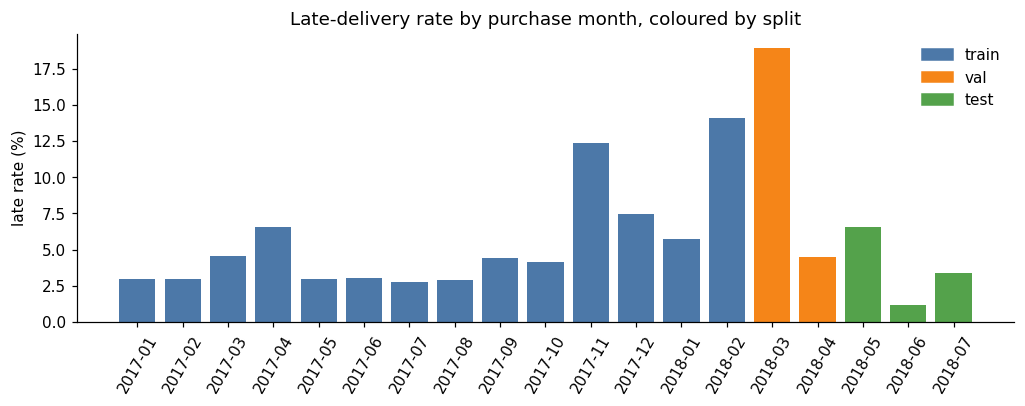

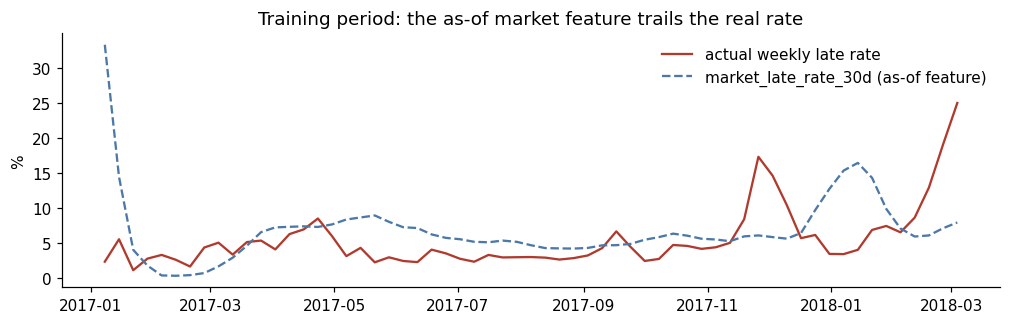

corr(weekly actual, weekly as-of market rate): 0.03


In [2]:
m = pop.groupby(["purchase_ym", "split"]).agg(orders=("late_day", "size"), late_rate=("late_day", "mean")).reset_index()
fig, ax = plt.subplots(figsize=(11, 3.4))
colors = {"train": "#4C78A8", "val": "#F58518", "test": "#54A24B"}
ax.bar(m.purchase_ym, m.late_rate * 100, color=m.split.map(colors))
handles = [plt.Rectangle((0, 0), 1, 1, color=c, label=s) for s, c in colors.items()]
ax.set_ylabel("late rate (%)"); ax.legend(handles=handles, frameon=False); ax.tick_params(axis="x", rotation=60)
ax.set_title("Late-delivery rate by purchase month, coloured by split")
save("late_rate_by_split"); plt.show()

w = tr.set_index("order_purchase_timestamp").resample("W").agg({"late_day": "mean", "market_late_rate_30d": "mean"})
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(w.index, w.late_day * 100, label="actual weekly late rate", color="#B03A2E")
ax.plot(w.index, w.market_late_rate_30d * 100, label="market_late_rate_30d (as-of feature)", color="#4C78A8", ls="--")
ax.set_ylabel("%"); ax.legend(frameon=False); ax.set_title("Training period: the as-of market feature trails the real rate")
save("market_feature_lag"); plt.show()
print("corr(weekly actual, weekly as-of market rate):", round(w.late_day.corr(w.market_late_rate_30d), 3))

**Finding.** Inside the training period alone the monthly late rate moves between 2.8% and 14.1%, with spikes in Nov 2017 (Black Friday, 12.4%) and Feb 2018 (14.1%). Validation (11.8%) and test (3.8%) sit at opposite extremes. The as-of feature `market_late_rate_30d` barely tracks the real weekly rate (correlation 0.03). A late outcome only becomes known after the promised date, about 3–4 weeks after purchase, so the feature peaks around six weeks *after* the Nov 2017 spike, when the real rate has already fallen back. Its January 2017 values are also inflated by the tiny 2016 history.

**Decision.** Keep the strictly chronological split and report metrics per test month. The two market features (`market_late_rate_30d`, `market_resolved_30d`) go into the ablation as a group, because a lagging signal can hurt during a drift period. A drift experiment (monthly retraining) is added to the decision analysis.

## 2. Does distance drive lateness?

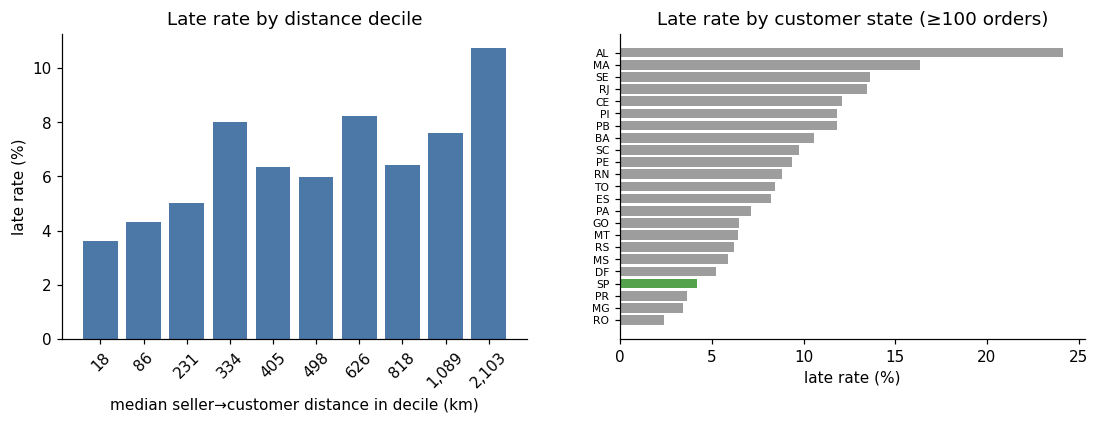

                 size      mean
all_same_state                 
cross-state     37993  0.078883
same state      19057  0.041192
states (>=100 orders), lowest and highest late rate:
                orders  late_rate
customer_state                   
RO                 167      0.024
MG                6876      0.034
PR                2898      0.037
SE                 220      0.136
MA                 477      0.164
AL                 261      0.241
Spearman(distance, late): 0.066


,orders,late_rate,median_km
dist_decile,,,
"(-0.001, 42.161]",5705,0.036284,18.386147
"(42.161, 140.457]",5705,0.043120,85.545732
"(140.457, 298.264]",5705,0.050307,230.932864
"(298.264, 359.46]",5705,0.079930,333.980203
"(359.46, 455.851]",5705,0.063453,405.073926
"(455.851, 551.388]",5705,0.059947,498.430469
"(551.388, 720.796]",5705,0.082209,626.394332
"(720.796, 894.157]",5705,0.064330,818.321944
"(894.157, 1472.631]",5705,0.076074,1089.104211


In [3]:
tr["dist_decile"] = pd.qcut(tr.distance_km_max, 10, duplicates="drop")
d = tr.groupby("dist_decile", observed=True).agg(orders=("late_day", "size"), late_rate=("late_day", "mean"),
                                                 median_km=("distance_km_max", "median"))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].bar(range(len(d)), d.late_rate * 100, color="#4C78A8")
axes[0].set_xticks(range(len(d)), [f"{v:,.0f}" for v in d.median_km], rotation=45)
axes[0].set_xlabel("median seller→customer distance in decile (km)"); axes[0].set_ylabel("late rate (%)")
axes[0].set_title("Late rate by distance decile")
st = tr.groupby("customer_state").agg(orders=("late_day", "size"), late_rate=("late_day", "mean")).sort_values("late_rate")
st = st[st.orders >= 100]
axes[1].barh(st.index, st.late_rate * 100, color=np.where(st.index.isin(["SP"]), "#54A24B", "#9D9D9D"))
axes[1].set_xlabel("late rate (%)"); axes[1].set_title("Late rate by customer state (≥100 orders)")
axes[1].tick_params(axis="y", labelsize=7)
save("distance_and_state"); plt.show()
same = tr.groupby("all_same_state").late_day.agg(["size", "mean"]).rename(index={0: "cross-state", 1: "same state"})
print(same)
print("states (>=100 orders), lowest and highest late rate:"); print(st.iloc[[0, 1, 2, -3, -2, -1]].round(3))
print("Spearman(distance, late):", round(stats.spearmanr(tr.distance_km_max, tr.late_day, nan_policy="omit")[0], 3))
d

**Finding.** The late rate rises from 3.6% in the nearest distance decile (median 18 km) to 10.7% in the farthest (median about 2,100 km), though not monotonically (overall Spearman only 0.066). Cross-state orders are late 7.9% of the time against 4.1% for same-state orders. The destination state matters even more: 2.4% (RO), 3.4% (MG) and 3.7% (PR) at the low end, against 13.6% (SE), 16.4% (MA) and 24.1% (AL) at the high end.

**Decision.** Keep `distance_km_max`, `all_same_state`, `customer_state` and the customer coordinates. The step-like, non-linear shape suits trees. For linear models distance is log1p-transformed, and the state is one-hot encoded.

## 3. Do some sellers fail repeatedly?

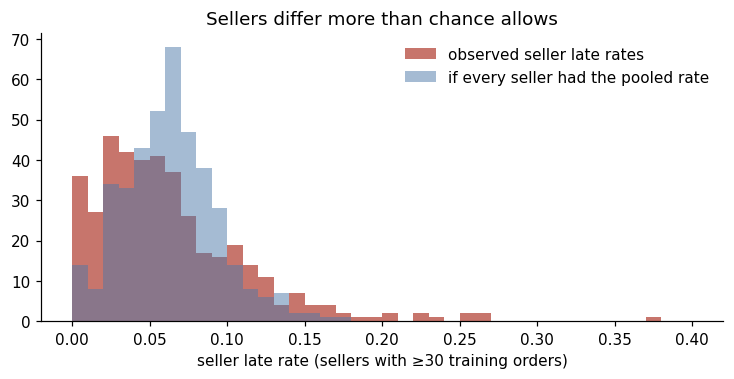

406 sellers with >=30 orders | pooled rate 0.063 | sd observed 0.055 vs chance 0.030 | overdispersion chi2=1,403, df=405, p=4.4e-110
single-feature (as-of) seller_late_rate_max         ROC-AUC 0.552  PR-AUC 0.081
single-feature (as-of) seller_late_rate_90d_max     ROC-AUC 0.553  PR-AUC 0.084
single-feature (as-of) route_late_rate_max          ROC-AUC 0.630  PR-AUC 0.123
single-feature (as-of) dest_state_late_rate         ROC-AUC 0.637  PR-AUC 0.120


In [4]:
sel = (load("items", usecols=["order_id", "seller_id"]).drop_duplicates()
       .merge(tr[["order_id", "late_day"]], on="order_id"))
by_seller = sel.groupby("seller_id").late_day.agg(n="size", late="sum")
big = by_seller[by_seller.n >= 30].copy()
big["rate"] = big.late / big.n
pooled = big.late.sum() / big.n.sum()
rng = np.random.default_rng(C.SEED)
sim = rng.binomial(big.n.to_numpy(), pooled) / big.n.to_numpy()
chi2 = (((big.late - big.n * pooled) ** 2) / (big.n * pooled * (1 - pooled))).sum()
p_disp = stats.chi2.sf(chi2, len(big) - 1)
fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.linspace(0, 0.4, 41)
ax.hist(big.rate, bins=bins, alpha=0.7, label="observed seller late rates", color="#B03A2E")
ax.hist(sim, bins=bins, alpha=0.5, label="if every seller had the pooled rate", color="#4C78A8")
ax.set_xlabel("seller late rate (sellers with ≥30 training orders)"); ax.legend(frameon=False)
ax.set_title("Sellers differ more than chance allows")
save("seller_overdispersion"); plt.show()
print(f"{len(big)} sellers with >=30 orders | pooled rate {pooled:.3f} | sd observed {big.rate.std():.3f} vs chance {sim.std():.3f}"
      f" | overdispersion chi2={chi2:,.0f}, df={len(big)-1}, p={p_disp:.1e}")
for f in ["seller_late_rate_max", "seller_late_rate_90d_max", "route_late_rate_max", "dest_state_late_rate"]:
    print(f"single-feature (as-of) {f:28s} ROC-AUC {roc_auc_score(tr.late_day, tr[f]):.3f}  PR-AUC {average_precision_score(tr.late_day, tr[f]):.3f}")

**Finding.** Sellers really do differ. Among 406 sellers with at least 30 training orders, late rates spread almost twice as wide as chance would allow (standard deviation 0.055 against 0.030; overdispersion χ² = 1,403 on 405 df, p ≈ 4e-110). Even so, the **as-of** seller late rate on its own is weak (ROC-AUC 0.552, PR-AUC 0.081 against a 0.066 base rate). Most orders come from sellers with little resolved history, and smoothing pulls them toward the market prior. The route and destination-state rates carry more signal (ROC-AUC 0.63–0.64, PR-AUC about 0.12).

**Decision.** Keep seller history together with the cold-start flag, since the heterogeneity is real. Route and destination-state rates are expected to carry more of the history signal, and the ablation will measure each group's contribution.

## 4. Are generous promises safer?

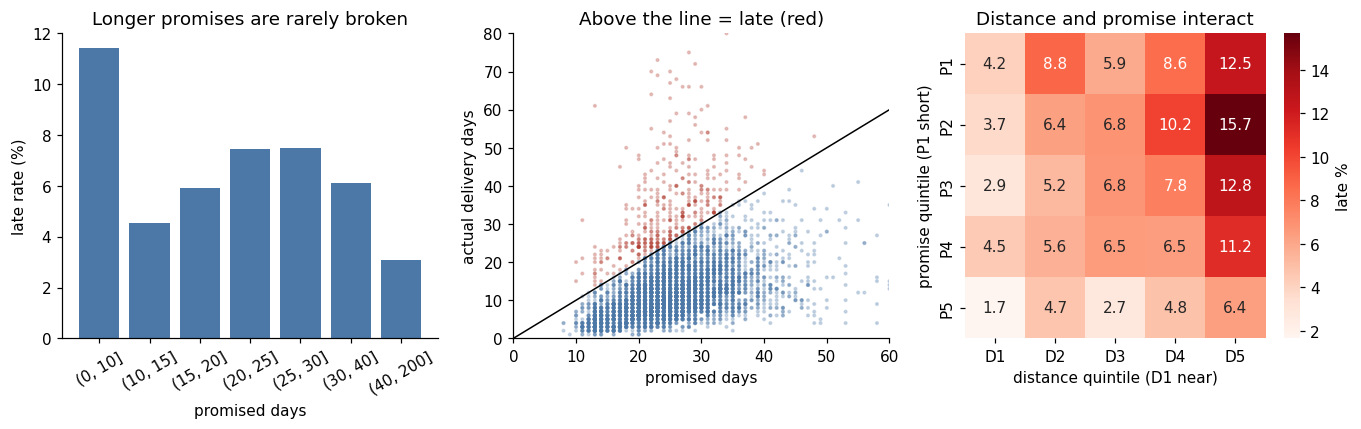

median promised days 25.0 | median actual days 11.0 | median slack (promised - actual) 13.0


,orders,late_rate
promise_bin,,
"(0, 10]",280,0.114286
"(10, 15]",4374,0.045267
"(15, 20]",8883,0.059102
"(20, 25]",17779,0.074526
"(25, 30]",13295,0.075066
"(30, 40]",10557,0.061192
"(40, 200]",1882,0.030818


In [5]:
tr["promise_bin"] = pd.cut(tr.promised_days, [0, 10, 15, 20, 25, 30, 40, 200])
pr = tr.groupby("promise_bin", observed=True).agg(orders=("late_day", "size"), late_rate=("late_day", "mean"))
tr["actual_days"] = (tr.order_delivered_customer_date.dt.normalize() - tr.order_purchase_timestamp.dt.normalize()).dt.days
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].bar(pr.index.astype(str), pr.late_rate * 100, color="#4C78A8"); axes[0].tick_params(axis="x", rotation=30)
axes[0].set_xlabel("promised days"); axes[0].set_ylabel("late rate (%)"); axes[0].set_title("Longer promises are rarely broken")
smp = tr.sample(6000, random_state=C.SEED)
axes[1].scatter(smp.promised_days, smp.actual_days, s=3, alpha=0.25, c=np.where(smp.late_day == 1, "#B03A2E", "#4C78A8"))
axes[1].plot([0, 60], [0, 60], color="k", lw=1); axes[1].set_xlim(0, 60); axes[1].set_ylim(0, 80)
axes[1].set_xlabel("promised days"); axes[1].set_ylabel("actual delivery days"); axes[1].set_title("Above the line = late (red)")
tr["dist_q"] = pd.qcut(tr.distance_km_max, 5, labels=[f"D{i}" for i in range(1, 6)])
tr["prom_q"] = pd.qcut(tr.promised_days, 5, labels=[f"P{i}" for i in range(1, 6)])
hm = tr.pivot_table(index="prom_q", columns="dist_q", values="late_day", aggfunc="mean", observed=True) * 100
sns.heatmap(hm, annot=True, fmt=".1f", cmap="Reds", ax=axes[2], cbar_kws={"label": "late %"})
axes[2].set_xlabel("distance quintile (D1 near)"); axes[2].set_ylabel("promise quintile (P1 short)")
axes[2].set_title("Distance and promise interact")
save("promises"); plt.show()
print("median promised days", tr.promised_days.median(), "| median actual days", tr.actual_days.median(),
      "| median slack (promised - actual)", (tr.promised_days - tr.actual_days).median())
pr

**Finding.** The relationship is not monotonic. Very short promises (10 days or less, only 280 orders) are late 11.4% of the time, the rate peaks at 20–30 days (7.5%), and promises over 40 days are late only 3.1%. Olist pads its promises: the median promise is 25 days against a median actual delivery of 11 days. Promise length is confounded with distance, because remote customers get longer promises. Holding distance fixed, the heatmap shows longer promises are safer (farthest quintile: 15.7% at P2 against 6.4% at P5). Holding the promise fixed, distance raises the risk.

**Decision.** Keep `promised_days` and `promised_business_days`. The distance × promise interaction is one reason to include tree models, since logistic regression only sees it through additive terms.

## 5. How much does lateness hurt reviews?

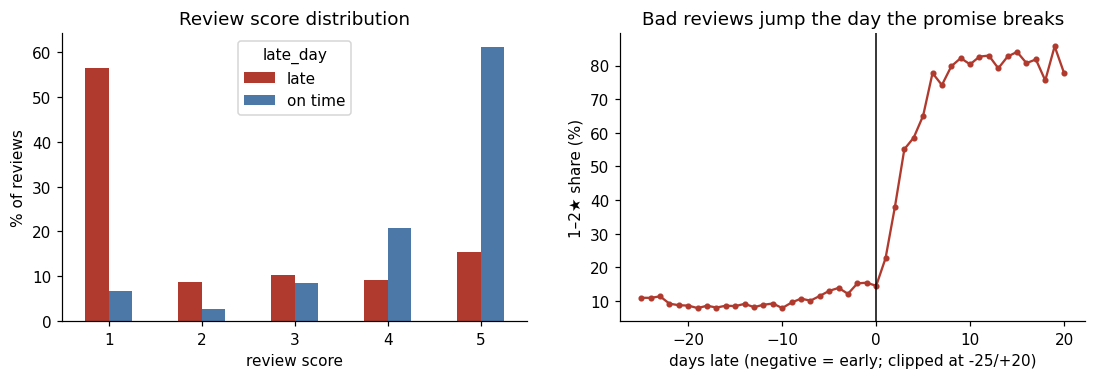

,orders,mean_score,bad_review_share
late_day,,,
on time,52926,4.268110,0.095038
late,3692,2.184453,0.651679


In [6]:
rv = load("reviews").sort_values("review_answer_timestamp").drop_duplicates("order_id", keep="last")
rt = tr.merge(rv[["order_id", "review_score"]], on="order_id", how="inner")
rt["days_late"] = (rt.order_delivered_customer_date.dt.normalize() - rt.order_estimated_delivery_date).dt.days
summary = rt.groupby("late_day").review_score.agg(orders="size", mean_score="mean",
                                                  bad_review_share=lambda s: (s <= 2).mean())
summary.index = summary.index.map({0.0: "on time", 1.0: "late"})
bucket = rt.assign(b=rt.days_late.clip(-25, 20)).groupby("b").review_score.agg(n="size", bad=lambda s: (s <= 2).mean())
bucket = bucket[bucket.n >= 30]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
dist = pd.crosstab(rt.late_day.map({0.0: "on time", 1.0: "late"}), rt.review_score, normalize="index") * 100
dist.T.plot.bar(ax=axes[0], color=["#B03A2E", "#4C78A8"]); axes[0].set_ylabel("% of reviews"); axes[0].set_xlabel("review score")
axes[0].set_title("Review score distribution"); axes[0].tick_params(axis="x", rotation=0)
axes[1].plot(bucket.index, bucket.bad * 100, marker="o", ms=3, color="#B03A2E"); axes[1].axvline(0, color="k", lw=1)
axes[1].set_xlabel("days late (negative = early; clipped at -25/+20)"); axes[1].set_ylabel("1–2★ share (%)")
axes[1].set_title("Bad reviews jump the day the promise breaks")
save("reviews_vs_lateness"); plt.show()
summary

**Finding.** Among training-period orders with a review, late orders average **2.18★** against **4.27★** for on-time orders, and 65.2% of late orders get a 1★ or 2★ review against 9.5% of on-time ones. The bad-review share stays flat at about 10% however early the parcel arrives, then jumps the moment the promise breaks, reaching about 80% one week late.

**Decision.** This confirms the business case for Task A and sets the scale of the damage assumption in the cost model (a late order is costly). It also shows that Task B needs `days_late` as a feature: the effect is a threshold at day 0, not a straight line.

## 6. Which numeric fields are heavy-tailed?

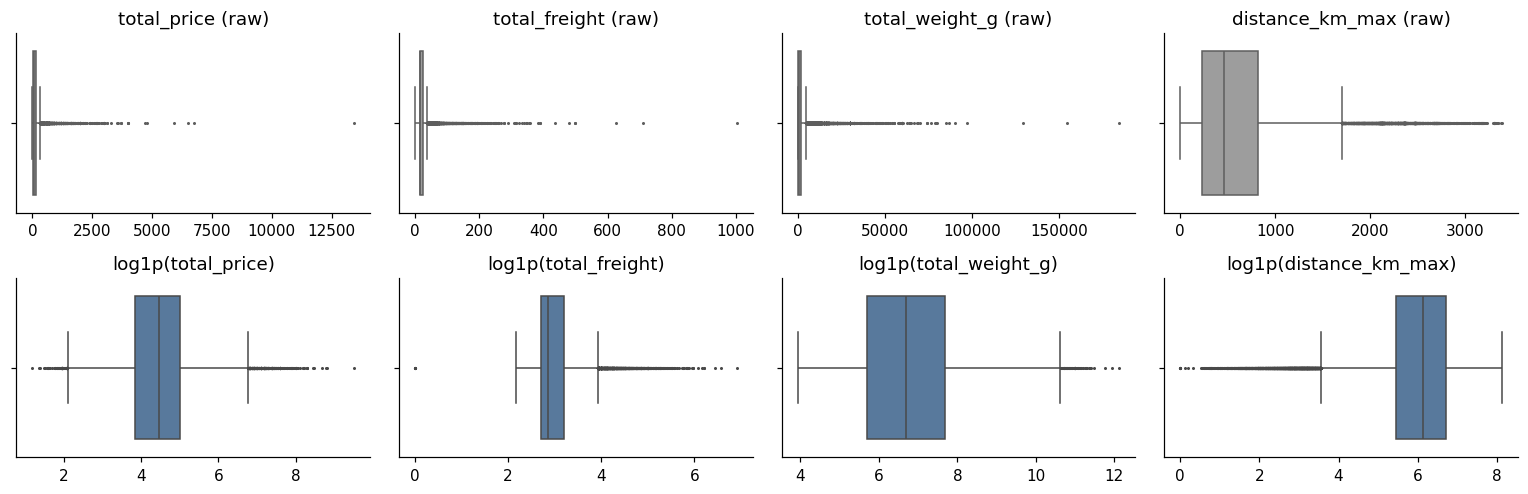

,skew,max,p99,median
n_seller_states,15.55,3.00,1.00,1.00
customer_prior_orders,13.71,9.00,1.00,0.00
total_price,11.47,13440.00,969.00,84.99
n_sellers,10.90,5.00,2.00,1.00
total_freight,9.08,1002.29,95.63,16.54
n_items,8.40,21.00,3.00,1.00
max_item_price,7.99,6735.00,899.00,79.00
total_volume_cm3,7.66,1476000.00,140520.36,7920.00
n_products,7.66,7.00,2.00,1.00
total_weight_g,6.44,184400.00,22600.00,800.00


In [7]:
num = FEATURES.index[FEATURES.kind == "num"]
sk = tr[num].skew().sort_values(ascending=False).rename("skew").to_frame()
sk["max"] = tr[num].max(); sk["p99"] = tr[num].quantile(0.99); sk["median"] = tr[num].median()
cols = ["total_price", "total_freight", "total_weight_g", "distance_km_max"]
fig, axes = plt.subplots(2, 4, figsize=(14, 4.6))
for i, c in enumerate(cols):
    sns.boxplot(x=tr[c], ax=axes[0, i], color="#9D9D9D", fliersize=1); axes[0, i].set_title(f"{c} (raw)")
    sns.boxplot(x=np.log1p(tr[c]), ax=axes[1, i], color="#4C78A8", fliersize=1); axes[1, i].set_title(f"log1p({c})")
    axes[0, i].set_xlabel(""); axes[1, i].set_xlabel("")
plt.tight_layout(); save("skew_boxplots"); plt.show()
sk.round(2).head(15)

**Finding.** Money and size fields are extremely skewed. `total_price` has skew 11.5 and a maximum of 13,440 BRL against a 99th percentile of 969. `total_freight` peaks at 1,002 BRL against a p99 of 96, and weights and volumes have skew 6–8. After log1p the distributions are close to symmetric (bottom row of the figure).

**Decision.** Inside the linear pipeline, apply log1p and then winsorise at the 1st and 99th training percentiles (`modeling.LOG_FEATURES`, `Winsorizer`). Trees get the raw values, because splits are unaffected by monotone transforms and outliers.

## 7. Which features are redundant?

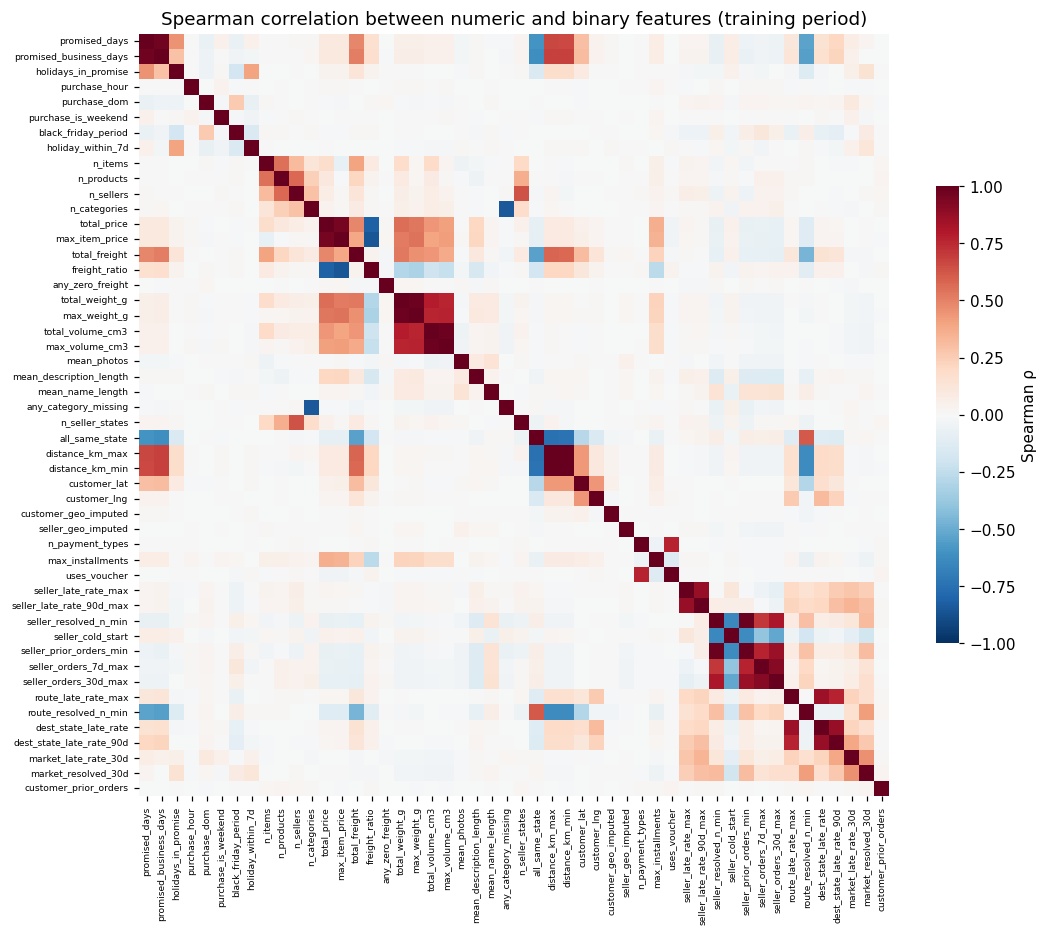

Feature pairs with |Spearman| >= 0.85:


,level_0,level_1,spearman,abs
972,distance_km_max,distance_km_min,0.997,0.997
1160,seller_resolved_n_min,seller_prior_orders_min,0.991,0.991
697,total_weight_g,max_weight_g,0.983,0.983
760,total_volume_cm3,max_volume_cm3,0.983,0.983
0,promised_days,promised_business_days,0.973,0.973
522,total_price,max_item_price,0.959,0.959
1189,seller_orders_7d_max,seller_orders_30d_max,0.912,0.912
1215,dest_state_late_rate,dest_state_late_rate_90d,0.871,0.871
1134,seller_late_rate_max,seller_late_rate_90d_max,0.868,0.868
1181,seller_prior_orders_min,seller_orders_30d_max,0.864,0.864


Cramér's V between categoricals:


,promise_dow,purchase_dow,purchase_month,main_category,customer_state,main_seller_state,main_payment_type
promise_dow,1.00,0.04,0.05,0.04,0.03,0.02,0.01
purchase_dow,0.04,1.00,0.05,0.04,0.02,0.02,0.03
purchase_month,0.05,0.05,1.00,0.08,0.03,0.05,0.02
main_category,0.04,0.04,0.08,1.00,0.05,0.22,0.06
customer_state,0.03,0.02,0.03,0.05,1.00,0.06,0.04
main_seller_state,0.02,0.02,0.05,0.22,0.06,1.00,0.03
main_payment_type,0.01,0.03,0.02,0.06,0.04,0.03,1.00


In [8]:
numeric = list(FEATURES.index[FEATURES.kind.isin(["num", "bin"])])
rho = tr[numeric].corr(method="spearman")
pairs = (rho.where(np.triu(np.ones(rho.shape, bool), 1)).stack().rename("spearman").reset_index()
         .assign(abs=lambda x: x.spearman.abs()).sort_values("abs", ascending=False))
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(rho, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, xticklabels=True, yticklabels=True,
            cbar_kws={"shrink": 0.6, "label": "Spearman ρ"})
ax.tick_params(labelsize=6); ax.set_title("Spearman correlation between numeric and binary features (training period)")
save("spearman_heatmap"); plt.show()

def cramers_v(a, b):
    t = pd.crosstab(a, b); chi2 = stats.chi2_contingency(t, correction=False)[0]
    r, k = t.shape; return np.sqrt(chi2 / len(a) / (min(r, k) - 1))
cats = list(FEATURES.index[FEATURES.kind == "cat"])
cv = pd.DataFrame([[cramers_v(tr[a], tr[b]) if a != b else 1.0 for b in cats] for a in cats], index=cats, columns=cats)
print("Feature pairs with |Spearman| >= 0.85:")
display(pairs[pairs["abs"] >= 0.85].head(20).round(3))
print("Cramér's V between categoricals:"); cv.round(2)

**Finding.** Twelve feature pairs have |ρ| ≥ 0.85. Near-duplicates include max and min distance (0.997), seller resolved count and prior orders (0.991), total and max weight (0.983), total and max volume (0.983), promised and business days (0.973), and total and max item price (0.959). The categoricals are almost independent of each other (Cramér's V ≤ 0.22, with the highest between main category and seller state).

**Decision.** Treat the second member of each near-duplicate pair as a *redundant* ablation group. If walk-forward PR-AUC is unchanged without them, drop them for a simpler model. Elastic-net logistic regression copes with the collinearity in the meantime, and trees are indifferent to it.

## 8. Is missingness random?

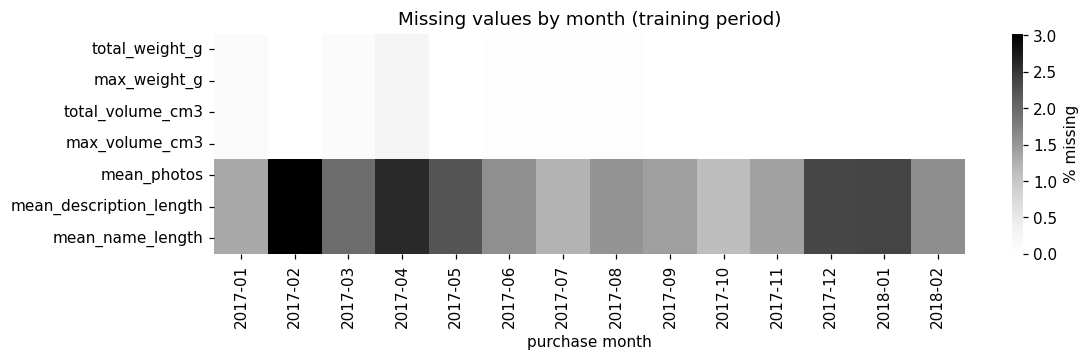

late rate when product text/photos are missing: 6.73 % vs 6.63 %
every order with missing photos has an item with missing category: True


,missing,pct
total_weight_g,16,0.028
max_weight_g,16,0.028
total_volume_cm3,16,0.028
max_volume_cm3,16,0.028
mean_photos,1025,1.797
mean_description_length,1025,1.797
mean_name_length,1025,1.797


In [9]:
na_cols = [c for c in FEATURES.index if tr[c].isna().any()]
miss = tr.groupby("purchase_ym")[na_cols].apply(lambda g: g.isna().mean() * 100)
fig, ax = plt.subplots(figsize=(11, 2.6))
sns.heatmap(miss.T, cmap="Greys", ax=ax, cbar_kws={"label": "% missing"}); ax.set_xlabel("purchase month")
ax.set_title("Missing values by month (training period)")
save("missingness"); plt.show()
print("late rate when product text/photos are missing:",
      round(tr.loc[tr.mean_photos.isna(), "late_day"].mean() * 100, 2), "% vs", round(tr.loc[tr.mean_photos.notna(), "late_day"].mean() * 100, 2), "%")
print("every order with missing photos has an item with missing category:",
      bool((tr.mean_photos.notna() | tr.any_category_missing.astype(bool)).all()))
tr[na_cols].isna().sum().rename("missing").to_frame().assign(pct=lambda x: (x.missing / len(tr) * 100).round(3))

**Finding.** Only 7 features have missing values: weight and volume for 16 orders (0.03%), and product photos and text lengths for 1,025 orders (1.8%). Every order with missing photos contains an item with a missing category. The missingness is spread evenly across months and carries no signal (6.73% late when missing against 6.63% when present).

**Decision.** Use median imputation plus a missing-value indicator, learned on training rows inside the linear pipeline. NaN is passed through to trees, which handle it natively. Category-level imputation is not worth it for 16 rows.

## 9. Calendar effects and the `purchase_month` question

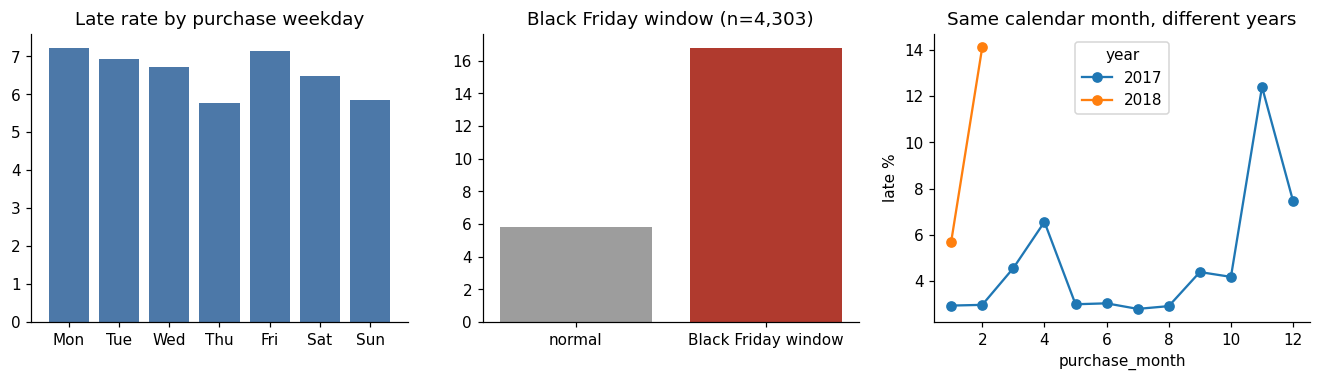

                      size      mean
black_friday_period                 
0                    52747  0.057994
1                     4303  0.168022
late % by weekday (Mon..Sun): [7.23, 6.93, 6.71, 5.77, 7.15, 6.5, 5.84]


year,2017,2018
purchase_month,,
1,2.9,5.7
2,3.0,14.1
3,4.6,NaN
4,6.6,NaN
5,3.0,NaN
6,3.0,NaN
7,2.8,NaN
8,2.9,NaN
9,4.4,NaN


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
dow = tr.groupby("purchase_dow").late_day.mean() * 100
axes[0].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], dow, color="#4C78A8"); axes[0].set_title("Late rate by purchase weekday")
bf = tr.groupby("black_friday_period").late_day.agg(["size", "mean"])
axes[1].bar(["normal", "Black Friday window"], bf["mean"] * 100, color=["#9D9D9D", "#B03A2E"])
axes[1].set_title(f"Black Friday window (n={bf.loc[1, 'size']:,})")
tr["year"] = tr.order_purchase_timestamp.dt.year
ym = tr.pivot_table(index="purchase_month", columns="year", values="late_day", aggfunc="mean") * 100
ym.plot(ax=axes[2], marker="o"); axes[2].set_title("Same calendar month, different years"); axes[2].set_ylabel("late %")
save("calendar"); plt.show()
print(bf); print("late % by weekday (Mon..Sun):", dow.round(2).tolist())
ym.round(1)

**Finding.** Weekday effects are small (5.8–7.2%). The Black Friday window is the one large, repeatable calendar effect: 16.8% late against 5.8% (n = 4,303). `purchase_month` ranks first of all single features, but the same calendar month behaves differently across years (January 2.9% in 2017 against 5.7% in 2018; February 3.0% against 14.1%). The test months, May to July, appear in training only once, in 2017, at about 3%. The month's apparent signal is the model memorising one-off episodes.

**Decision.** **Drop `purchase_month`** (to be confirmed by walk-forward CV in the ablation, where a memorised month should not help). Keep `black_friday_period` and `holiday_within_7d`, which describe the repeatable peak without tying it to one year.

## 10. Which single features carry signal?

Each feature is scored on its own against `late_day` on the training period (ROC-AUC folded so that 0.5 = no signal; categoricals use their in-sample late rate per level, which is optimistic and only used for ranking).

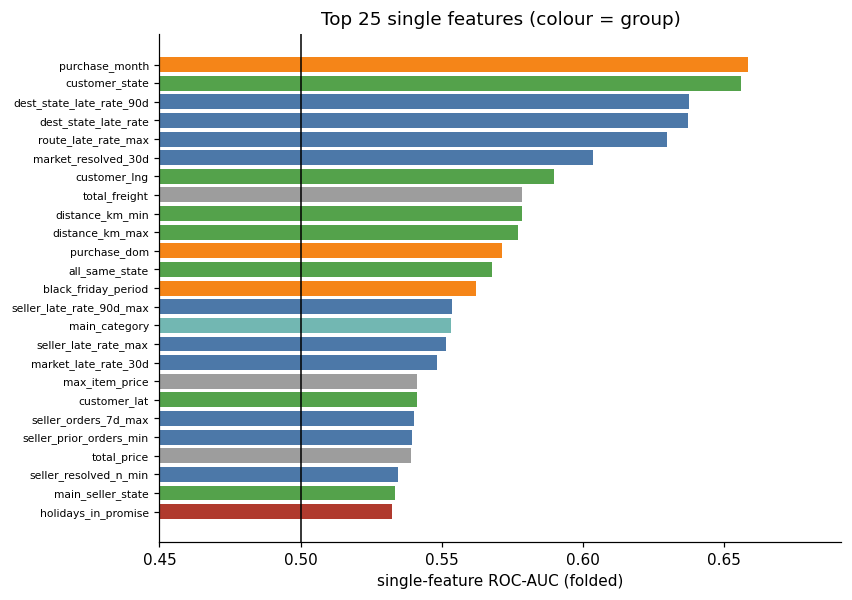

base rate 0.066


,group,auc_folded,direction,pr_auc
feature,,,,
purchase_month,calendar,0.659,+,0.106
customer_state,geography,0.656,+,0.113
dest_state_late_rate_90d,history,0.637,+,0.134
dest_state_late_rate,history,0.637,+,0.120
route_late_rate_max,history,0.630,+,0.123
market_resolved_30d,history,0.604,+,0.083
customer_lng,geography,0.590,+,0.094
total_freight,basket,0.578,+,0.083
distance_km_min,geography,0.578,+,0.085


In [11]:
rows = []
for f in FEATURES.index:
    x = tr[f]
    if FEATURES.loc[f, "kind"] == "cat":
        x = x.map(tr.groupby(f, observed=True).late_day.mean())
    x = x.astype(float).fillna(x.median())
    auc = roc_auc_score(tr.late_day, x)
    rows.append({"feature": f, "group": FEATURES.loc[f, "group"], "auc_folded": max(auc, 1 - auc),
                 "direction": "+" if auc >= 0.5 else "−", "pr_auc": average_precision_score(tr.late_day, x if auc >= 0.5 else -x)})
uni = pd.DataFrame(rows).set_index("feature").sort_values("auc_folded", ascending=False)
fig, ax = plt.subplots(figsize=(8, 6))
top = uni.head(25)[::-1]
ax.barh(top.index, top.auc_folded, color=top.group.map({"promise": "#B03A2E", "history": "#4C78A8", "geography": "#54A24B",
                                                           "calendar": "#F58518", "basket": "#9D9D9D", "product": "#72B7B2",
                                                           "payment": "#E45756"}))
ax.axvline(0.5, color="k", lw=1); ax.set_xlim(0.45, None); ax.tick_params(axis="y", labelsize=7)
ax.set_xlabel("single-feature ROC-AUC (folded)"); ax.set_title("Top 25 single features (colour = group)")
save("univariate_signal"); plt.show()
print(f"base rate {tr.late_day.mean():.3f}")
uni.round(3).head(25)

**Finding.** Leaving aside `purchase_month` (see section 9), the strongest single signals are geographic: the customer state, the destination-state and route late rates, longitude and distance. Black Friday and freight follow. No feature exceeds a folded ROC-AUC of 0.66, and seller history sits near 0.55.

**Decision.** No single feature or simple rule is enough. Feature selection uses group ablations under walk-forward CV (Stage 5) rather than univariate filters, which would keep `purchase_month` for the wrong reason.

## 11. Decisions carried into modelling

| # | Question | Decision |
|---|---|---|
| 1 | Does the late rate drift? | Chronological split, per-month reporting, market features on trial, drift experiment |
| 2 | Does distance matter? | Keep distance, same-state and state; log1p for linear models |
| 3 | Do sellers differ? | Yes, but as-of seller history is weak alone; keep it with route and state rates |
| 4 | Are long promises safer? | Keep both promise features; include trees for the distance × promise interaction |
| 5 | Does lateness hurt reviews? | Yes, about 7× more bad reviews; sets the damage scale for the cost model; motivates Task B |
| 6 | Heavy tails? | log1p + 1/99% winsorising, linear models only |
| 7 | Redundancy? | Near-duplicate group goes to the ablation |
| 8 | Missingness? | Median + indicator for linear models; native NaN for trees |
| 9 | Calendar? | Drop `purchase_month` (memorisation); keep Black Friday and holiday flags |
| 10 | Single-feature signal? | No feature exceeds ROC-AUC 0.66, so the signal is spread out and models must combine features |

In [12]:
print(f"notebook runtime {time.perf_counter()-T0:.1f}s | final RSS {rss()}")

notebook runtime 18.3s | final RSS 660 MB
